In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [13]:
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP
kaiming_init = (5/3)/((n_embd*block_size)**0.5)

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * kaiming_init
b1 = torch.randn(n_hidden,                        generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01
b2 = torch.randn(vocab_size,                      generator=g) * 0 

bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2,b1, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [14]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
 
for i in range(max_steps):
    
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
    # Xb = [32, 3] emb = [32, 3, 10] 
    
    # forward pass
    emb = C[Xb] # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1) # concatenate into (N, block_size * dimensionality)
    # LINEAR LAYER
    hpreact = embcat @ W1 + b1 # hidden layer pre-activation
    # BatchNorm Layer
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True) 
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

    with torch.no_grad(): 
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    # Non-Linearity Layer 
    h = torch.tanh(hpreact) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function
    
    # backward pass
    for p in parameters: 
        p.grad = None
    loss.backward()
    
    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad
    
    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    break

    

      0/ 200000: 3.3147


In [15]:
# calibrate batch norm at the end of training - useful component in inference 
with torch.no_grad(): 
    emb = C[Xtr] 
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1 
    # measure mean/std 
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)

     

In [16]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 + b1 
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias #batch norm
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y) #Cross-entropy measures how bad those probabilities are compared to the correct answer.
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 3.2687273025512695
val 3.2683331966400146


In [17]:
# sample for the model 
g = torch.Generator().manual_seed(2147483647 + 10) 

for _ in range(20): 

    out = [] 
    context = [0] * block_size 
    while True: 
        # forward pass to the neural network 
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1) 
        logits = h @ W2 + b2 
        probs = F.softmax(logits, dim=1) 
        
        # sample from the distribution 
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        # shift the context window and track the samples 
        context = context[1:] + [ix] 
        out.append(ix) 
        # if we sample the special . token, break 
        if ix == 0:
            break 

    print(''.join(itos[i] for i in out)) # decode and print the generated word 

cbrpzhxqtbfhqvkfkwmrpxqthtykhkcaqskejrzhnbnfqpwsyhc.
vgqhiu.
rrmuqptcmziivdyxlhggphhbmgpoindqbqjtzsrlixwa.
vvdbquwqzthogdjaryxixfkqeupiusdbwed.
ecoia.
gtlffhysflquhpqgmbvdjhksyjrpmqqosozswjcojq.
wycjifrenqkpfsadlnuo.
zoebsrkoiazhrynhg.
opklhynrxyh.
xqioloqbplbvbwdn.
ipvqmuitjpbvfpzpddgpycsislqwkkmconzauqnyjydpk.
kvweskatikzamdtevl.
ky.
qdyctoorowooktbymouokfbfcw.
zoindzcs.
nu.
eoaignqqeroqci.
ipjzykbadyieluglconwzyzdjokhnlhjjqsxmuadltjhvtoyaplwuw.
xisxwrmfv.
qphtzbiuzzsrvgmknbfyntiysfgdglnmmj.


In [14]:
# Manipulate the Backbone structure of the MLP Neural Language Model 

# A. Softmax turns raw scores into probabilities. 
# 1. Scrutinize the initial loss: at run time the model should deem all 27 characters equally to come next (Softmax is confidently wrong) 
# This uniform distrubution should retreive a relatively low loss, but this model does not show it. 
# In theory, the loss is the negative log probability 
# To solve this, let all logits at initialization be equal to 0 zero 
# let b2 be 0, and W2 be a very small number (0.01)
# This will fix 3 things: 1) initialization loss is default 2) the loss plot doesn't have a hockey puck appearance anymore 3) the eval loss is smaller


# 2. Scrutinize the oversaturated tanh preactivation layer that can lead to dead neurons. 
# When you have a large hpreact (pre-activation node values) that are relatively large, the tanh gets saturated as it becomes -1 or 1 
# in the backward pass now, having a saturated hpreact means the local gradient is being multiplied by 0, creating a dead neuron. 
# using a tensor bool graph, you can see visually if there are any dead neurons 
# to offset this, we make W1 as appropriately scaled and same with b1 so that hpreact is closest to 0 
# if hpreact is too small, the model learns slowly - if too big, the risk of dead neurons occurs -> appropirately scaled via kaiming init

# 3. Scrutinizing our arbitrary offsets: enter kaiming int 
# you want the standard deviation of the pre-activation values to be as small as possible (least far-apart) 
# as you take the dot product, the mean at each product may be 0 but the variance adds, creating a bigger std
# So deeper neural networks can cause activations to become progressively more extreme if we don't control their scale.

# mathematically, you want to now divide the weights by the square root of the faning - number of inputs
# however, an article of refining rectifiers delved into the offset of sqrt s/n1 - where n1 is faning, 
# they also summed up that an optimized forward pass is projected to the backpropogation pass 
# pytorch implements the kaiming initialization - and now its the standard way of initializing neural networks. 

# this section has been evolved by modern revolution advances in initialization; for example: residual batch_normalization, and Adam as 
# the optimization loop (instead of  gradient descent) - in practice its best to offset the weight matrix by the sqrt of the fan_in 


#  4. Batch Normalization 
# instead of trying to get hpreact to be like a gausian distribution, why not just make it a gausian distribution 
# you do this by taking the preactivation values and taking the (1 - mean) / standard_deviation
# but you dont want a gausian pre_activation on every run, you want the model to move it around so it can learn which direction to minimize loss
# to acheive this, you ofset it by a bngain and bnbias (a tensor of 1s in a 1, 200) and ( a tensor of 0s in a 1,200) 
# the bngain will multiply the hpreact and add bnbias across all renditions of your model 
# the bngain and bnbias will learn during training (as parameters) how to render the lowest loss. 
# this in turn removes the major overhead that comes with initialization and prevent the variance sums to create saturated neurons 
# happoens to have a regularizer effect, wherein because a singular input is influenced by its batch (mean/std), it kind of learns 
# to filter out the noise in the data (pre-activations that are just to aggressively big), so it has this regularizer effect to 
# not just memorize the training data and to not overfit certain inputs. 
# now in a production setting, you dont want the model to be used to taking in batches, but just one input
# fix this by creating a bnmean and bnstd based on results from testing, and then use that in inference (using those learned parameters) 
# batch norm has its own bias layer, so adding a linear layer b1 in preactivation will be subtracted out by bnmean. Its not useful and wasteful 

# Not a fun normalization because of the coupling consequence - others are group normalization and layer normalization 



# 5. Pytorch-ify the linear layer, batchnorm, and non-linearity 


# 6. Get acquainted with the Diagnostic tools for evaluating a Neural Network 

# - Tanh preactivation histogram 
# - Gradient descent histogram 

# The importance of having a non linearity is that if it was all linear layers, it would have an effect of one big linear layer 

(tensor([0.2500, 0.2500, 0.2500, 0.2500]), tensor(1.3863))

In [40]:
# 5. Pytorch-ify the Neural Network - last Step before RNN


# Lets build and Train a deep neural network 
class Linear: 
    def __init__(self, fan_in, fan_out, bias=True): 
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5 # Because of Batch Norm this doesnt matter much either 
        self.bias = torch.zeros(fan_out) if bias else None 

    def __call__(self, x): 
        self.out = x @ self.weight 
        if self.bias is not None: 
            self.out += self.bias 
        return self.out 

    def parameters(self): 
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d: 

    def __init__(self, dim, eps=1e-5, momentum=0.01): 
        self.eps = eps 
        self.momentum = momentum 
        self.training = True 
        # Parameters 
        self.beta = torch.zeros(dim)
        self.gamma = torch.ones(dim) 
        # Buffers
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x): 
        # calculate the forward pass 
        if self.training: 
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True) 
        else: 
            xmean = self.running_mean
            xvar = self.running_var 
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # closer to paper 
        self.out = self.gamma * xhat + self.beta 

        if self.training:  # update running means/var in training
            with torch.no_grad(): 
                self.running_mean = (1-self.momentum) * self.running_mean + self.momentum * xmean # smoothly veer towards model specific mean 
                self.running_var = (1-self.momentum) * self.running_var + self.momentum * xvar 
        return self.out 

    def parameters(self): 
        return [self.gamma, self.beta] 

class Tanh: 
    def __call__(self, x): 
        self.out = torch.tanh(x) 
        return self.out 
    def parameters(self): 
        return [] 

n_embed = 10  # embed size 
n_hidden = 100 # neuron layer 
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embed), generator=g)
layers = [
    Linear(n_embed * block_size, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(            n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(            n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(            n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(            n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(            n_hidden, vocab_size),  BatchNorm1d(vocab_size),
    ]


# Apply fixes on 1,2,3 
with torch.no_grad(): 
    # fix 1: remove confidence from output softmax 
    layers[-1].gamma *= 0.01 
    #layers[-1].weight *= 0.01 
    # fix 2/3: apply gain to all weights 
    for layer in layers[:-1]: 
        if isinstance(layer, Linear): 
            layer.weight *= 5/3 # this doesnt have much effect because of how the activations are scaled in the Batch Normalization # MORE ROBUST

parameters = [C] + [p for layer in layers for p in layer.parameters()] 
print(sum(p.nelement() for p in parameters)) 
for p in parameters: 
    p.requires_grad = True 


                

47551


In [41]:
# Optimization Layer - pretty much the same 

max_steps = 200000
batch_size = 32
lossi = []
ud = [] 

for i in range(max_steps):
    
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] # Xb = [32, 3] emb = [32, 3, 10] 
    
    # forward pass
    emb = C[Xb] # embed the characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate into (N, block_size * dimensionality)
    
    # LINEAR LAYER + BATCHNORM + TANH (non-linearity)
    for layer in layers: 
        x = layer(x) 
    loss = F.cross_entropy(x, Yb) # loss 

    # backward pass
    for layer in layers: 
        layer.out.retain_grad()  # retain the activations gradients (derivative) for Graph Purposes 
    for p in parameters: 
        p.grad = None # zero-reset  
    loss.backward()
    
    # update
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad
    
    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad(): 
        ud.append([(lr*p.grad.std() / p.data.std()).log10().item() for p in parameters])

    if i >= 1000:
        break 


      0/ 200000: 3.2945


layer 2 (      Tanh): mean -0.00, std 0.64, saturated: 2.44%
layer 5 (      Tanh): mean -0.00, std 0.64, saturated: 2.53%
layer 8 (      Tanh): mean -0.00, std 0.64, saturated: 2.06%
layer 11 (      Tanh): mean +0.00, std 0.65, saturated: 1.84%
layer 14 (      Tanh): mean +0.00, std 0.65, saturated: 2.12%


Text(0.5, 1.0, 'activation distribution')

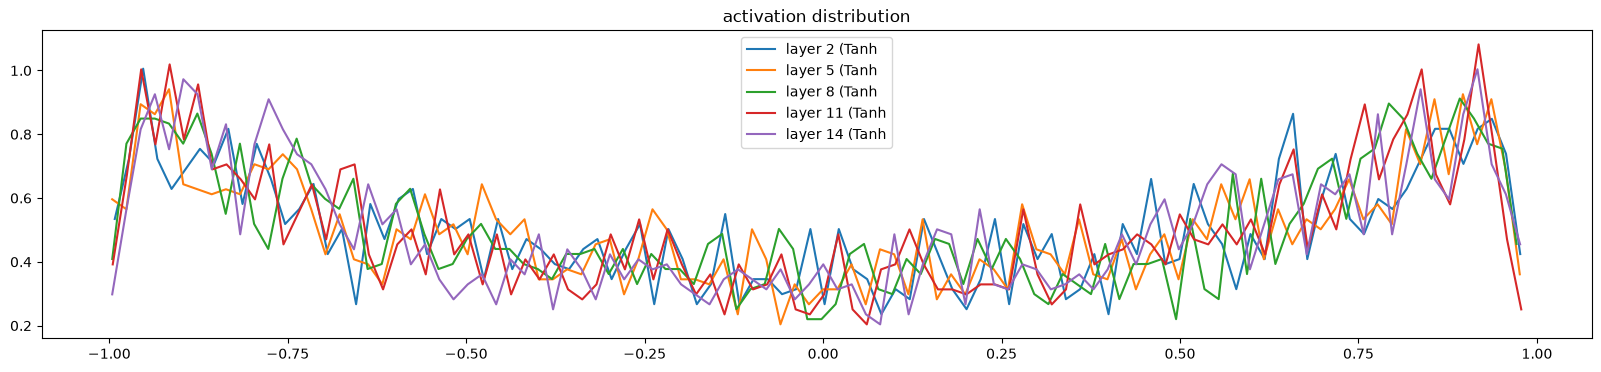

In [42]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

# if no squiggly lines, and then ends are high - the preactivation layer is oversaturated 
# if squiggly lines + low ends - the preactivation layer is not saturated 

layer 2 (      Tanh): mean -0.000000, std 3.697593e-03
layer 5 (      Tanh): mean -0.000000, std 3.171129e-03
layer 8 (      Tanh): mean +0.000000, std 2.986557e-03
layer 11 (      Tanh): mean -0.000000, std 2.787997e-03
layer 14 (      Tanh): mean +0.000000, std 2.693773e-03


Text(0.5, 1.0, 'gradient distribution')

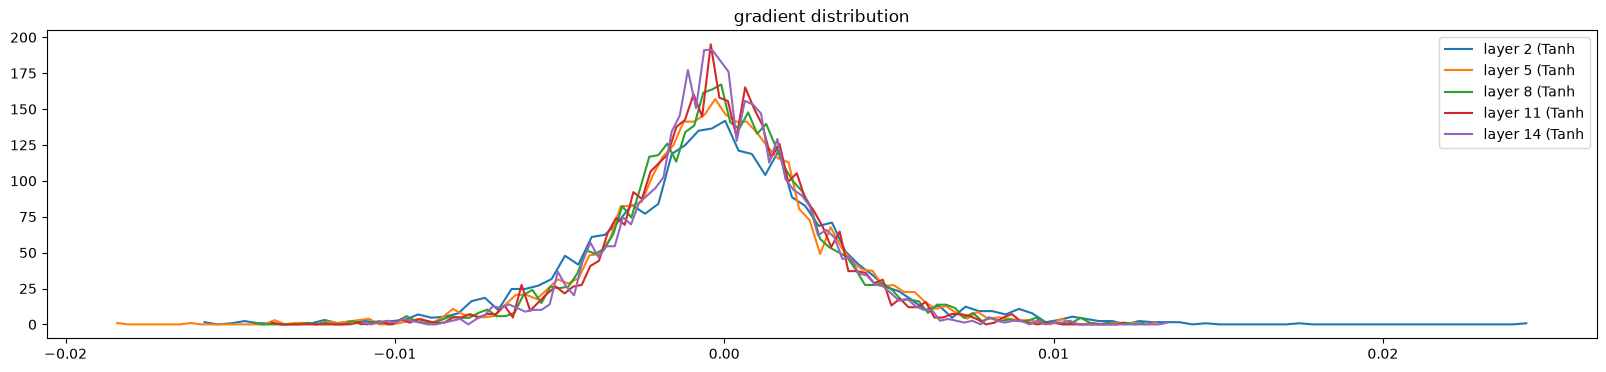

In [43]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

# If the movement is from large distrubutions to small, that means gradients are small
# if movement is small to large distribution, that means gradients are large

weight   (27, 10) | mean +0.000000 | std 9.952184e-03 | grad:data ratio 9.942511e-03
weight  (30, 100) | mean +0.000094 | std 8.462942e-03 | grad:data ratio 2.708359e-02
weight (100, 100) | mean +0.000066 | std 7.642792e-03 | grad:data ratio 4.574532e-02
weight (100, 100) | mean +0.000060 | std 6.401239e-03 | grad:data ratio 3.797069e-02
weight (100, 100) | mean -0.000029 | std 5.695419e-03 | grad:data ratio 3.394469e-02
weight (100, 100) | mean +0.000083 | std 5.653197e-03 | grad:data ratio 3.368111e-02
weight  (100, 27) | mean -0.000227 | std 1.089343e-02 | grad:data ratio 6.543022e-02


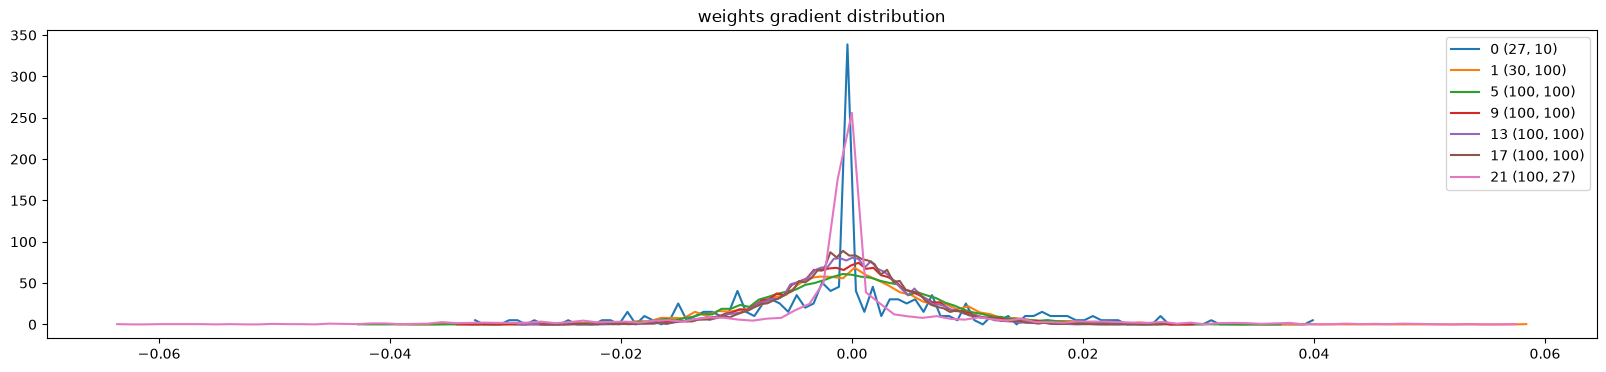

In [44]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

# You want the parameters to have useful value, 

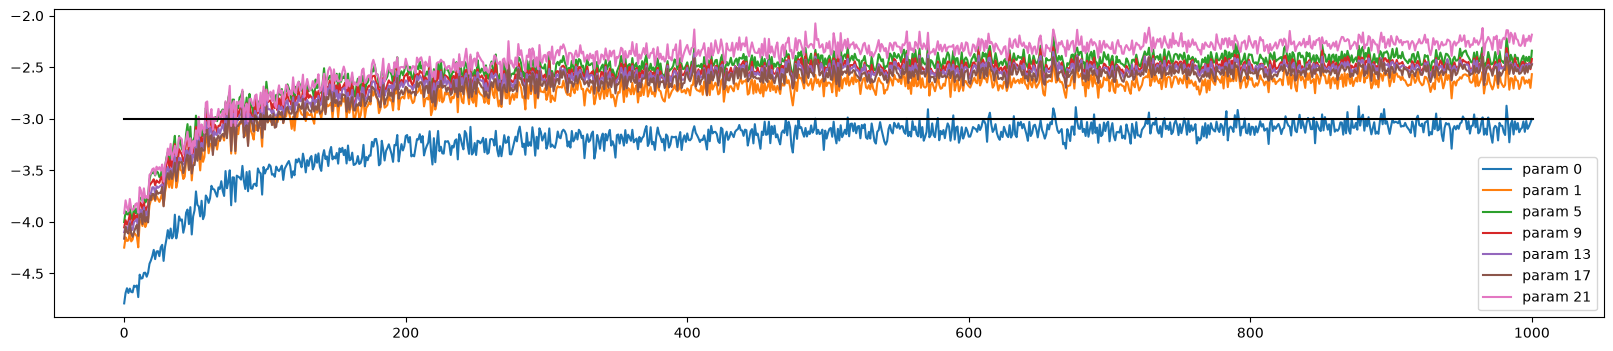

In [45]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

# if layer below k, parameters are not learning fast enough 
# if layer above k, learning fairly quick 